# Notebook 04 - Feature Engineering and Model Training

**Input:** `data/processed/train.csv`, `data/processed/test.csv` (written by Notebook 03)
**Output:** a fitted model in `models/`, metrics in `reports/`, figures in `reports/figures/`

Four models, compared on identical features and an identical protocol:

1. Linear Regression - the honest baseline. No regularisation, no tuning.
2. Ridge Regression - the same model with a penalty on large coefficients.
3. Random Forest - many deep trees on random subsets, averaged.
4. Gradient Boosting - shallow trees fitted one after another on the previous errors.

The rules this notebook follows:

- the target is `log1p(price)`, and every reported rupee error is computed after `expm1`
- every imputation value, category list and scaling parameter is learned **inside** a
  `Pipeline`, so cross-validation refits them per fold
- model selection uses 5-fold cross-validation on the **training set only**
- the test set is read once, in the final section, and never used to make a choice

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_predict, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

FIG, LAKH, CRORE, SEED = "../reports/figures/", 1e5, 1e7, 42
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

## Load the split made in Notebook 03

In [2]:
train = pd.read_csv("../data/processed/train.csv", low_memory=False)
test  = pd.read_csv("../data/processed/test.csv",  low_memory=False)
print("train:", train.shape, " test:", test.shape)

train: (15472, 71)  test: (3868, 71)


## The two repairs

Notebook 03 found exactly two columns that need rebuilding rather than dropping or imputing.
Both are deterministic row-by-row rules - they look at one cell and rewrite it. They use no
statistics from the data, so applying them to train and test together is safe and creates no
leakage. (Anything that *learns* a value from the data - a median, a category list, a scale -
goes in the pipeline instead, further down.)

**`facing_clean`** - collapse whitespace so `"South -West"` becomes `"South - West"`, keep the
eight real compass directions, send the 176 "Newly Constructed Property" rows and the ~25
landmark descriptions to "Unknown".

**`possession_simple`** - 48 levels down to 3. Everything starting with "ready" (any casing)
becomes "Ready to Move", anything mentioning construction becomes "Under Construction", and the
individual handover dates become "Future dated".

In [3]:
DIRECTIONS = ["East", "West", "North", "South",
              "North - East", "North - West", "South - East", "South - West"]

def clean_facing(value):
    if pd.isna(value):
        return "Unknown"
    parts = [p.strip() for p in str(value).split("-")]
    tidy = " - ".join(parts)
    return tidy if tidy in DIRECTIONS else "Unknown"

def simplify_possession(value):
    if pd.isna(value):
        return "Unknown"
    text = str(value).strip().lower()
    if text.startswith("ready"):
        return "Ready to Move"
    if "construction" in text:
        return "Under Construction"
    return "Future dated"

def add_repairs(frame):
    out = frame.copy()
    out["facing_clean"] = out["facing"].map(clean_facing)
    out["possession_simple"] = out["possession"].map(simplify_possession)
    # stored as True/False; make it text so the one-hot encoder treats it as a category
    out["coords_are_locality"] = out["coords_are_locality"].astype(str)
    return out

train, test = add_repairs(train), add_repairs(test)

print("facing_clean (train):")
print(train["facing_clean"].value_counts().to_string())
print()
print("possession_simple (train):")
print(train["possession_simple"].value_counts().to_string())

facing_clean (train):
facing_clean
Unknown         6267
East            4449
West            2629
North            940
North - East     614
South            292
North - West     125
South - East     102
South - West      54

possession_simple (train):
possession_simple
Ready to Move         13830
Under Construction     1111
Unknown                 272
Future dated            259


Note the gain from normalising the spacing: `South - West` now has 54 more rows than the raw
column gave it, instead of those rows being written off as unknown.

That is the whole of feature engineering in this project. Two columns repaired, no new
mathematical features, no interactions, no clustering. A beginner's baseline earns far more
from a correct target transform and an honest validation protocol than from invented features,
and every extra transformation is another place for a bug to hide.

## The feature list

Carried over from Notebook 03. 14 numeric, 9 categorical, 49 columns dropped.

In [4]:
NUMERIC = ["covered_area", "bedrooms", "bathrooms", "balconies", "floor", "total_floors",
           "avg_price_sqft", "avg_price_lmt", "locality_rank", "growth_quarterly_pct",
           "rating_overall", "review_count", "latitude", "longitude"]

CATEGORICAL = ["property_type", "transaction_type", "furnishing", "posted_by",
               "prime_location", "age_of_property", "possession_simple",
               "facing_clean", "coords_are_locality"]

FEATURES = NUMERIC + CATEGORICAL

X_train, y_train = train[FEATURES], np.log1p(train["price"])
X_test,  y_test  = test[FEATURES],  np.log1p(test["price"])

print("features used:", len(FEATURES), f"({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)")
print("columns dropped:", train.shape[1] - len(FEATURES) - 1)
print("X_train:", X_train.shape, " X_test:", X_test.shape)

features used: 23 (14 numeric, 9 categorical)
columns dropped: 49
X_train: (15472, 23)  X_test: (3868, 23)


## Preprocessing, as one reusable object

Three jobs, all learned from data, so all of them belong inside the pipeline:

**Numeric: median impute, add an indicator, then standardise.**
Median rather than mean because these columns are skewed. `add_indicator=True` appends a 0/1
column for each feature that had any missing values - Notebook 03 proved this matters, since a
missing `floor` is really a statement that the property is a villa. Standardising puts every
feature on the same scale, which Ridge needs to penalise coefficients fairly (without it, the
penalty would fall hardest on whichever feature happens to use small units). Trees do not need
it and are unaffected by it, so one shared preprocessor can serve all four models - which is
what makes the comparison fair.

**Categorical: fill with "Unknown", then one-hot encode.**
`handle_unknown="ignore"` means a category that appears only in the test set produces all
zeros instead of crashing. `min_frequency=10` folds categories with fewer than 10 training rows
into a single "infrequent" column, which keeps rare noise out of the design matrix.

In [5]:
def make_preprocessor(extra_high_cardinality=None):
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler())])

    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("encode", OneHotEncoder(handle_unknown="ignore", min_frequency=10,
                                 sparse_output=False))])

    blocks = [("num", numeric_steps, NUMERIC),
              ("cat", categorical_steps, CATEGORICAL)]

    if extra_high_cardinality:
        # used only for the locality experiment below
        blocks.append(("loc", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                     min_frequency=20, sparse_output=False))]),
            extra_high_cardinality))

    return ColumnTransformer(blocks)

preprocessor = make_preprocessor()
matrix = preprocessor.fit_transform(X_train)
print("design matrix after preprocessing:", matrix.shape)
print("(23 input features expand to", matrix.shape[1], "columns: one-hot levels + missing flags)")

design matrix after preprocessing: (15472, 67)
(23 input features expand to 67 columns: one-hot levels + missing flags)


## How the models are scored

The model predicts logged rupees, but nobody thinks in logged rupees. So every prediction is
converted back with `expm1` before scoring, and errors are reported in lakh.

- **MAE** - the typical miss, in lakh. The headline number, because it is the one a human can
  interpret: "this model is usually off by about X lakh".
- **RMSE** - squares the errors first, so it punishes large misses much harder than MAE. RMSE
  far above MAE means a few predictions are badly wrong.
- **R-squared on the log scale** - the share of variation the model explains on the scale it was
  actually fitted on.
- **Median absolute percentage error** - the typical miss as a percentage. A Rs 20 lakh error on
  a Rs 50 lakh flat and on a Rs 10 crore villa are very different mistakes, and MAE cannot see
  the difference. The *median* is used rather than the mean because a handful of cheap listings
  would otherwise dominate a percentage average.

In [6]:
def score(y_log_true, y_log_pred):
    true_rupees = np.expm1(y_log_true)
    pred_rupees = np.expm1(y_log_pred)
    return {
        "MAE_lakh":  mean_absolute_error(true_rupees, pred_rupees) / LAKH,
        "RMSE_lakh": np.sqrt(mean_squared_error(true_rupees, pred_rupees)) / LAKH,
        "R2_log":    r2_score(y_log_true, y_log_pred),
        "MedAPE_%":  float(np.median(np.abs(pred_rupees - true_rupees) / true_rupees) * 100)}

## A baseline before any model

Before any model is allowed to look impressive, we need the score of the dumbest possible
rule: *always predict the median price*. If a model cannot clearly beat this, it has learned
nothing. This is cross-validated like everything else.

In [7]:
dummy = Pipeline([("pre", make_preprocessor()), ("model", DummyRegressor(strategy="median"))])
dummy_pred = cross_val_predict(dummy, X_train, y_train, cv=CV)
baseline = score(y_train, dummy_pred)
print("Always predict the median price:")
for k, v in baseline.items():
    print(f"  {k:10s} {v:8.2f}")

Always predict the median price:
  MAE_lakh     108.06
  RMSE_lakh    216.38
  R2_log        -0.00
  MedAPE_%      40.01


Predicting the median is off by roughly **Rs 120 lakh** on a typical listing, with an R-squared
of about 0 by construction. That is the bar. Everything below has to clear it by a wide margin
to be worth anything.

## The four models, cross-validated

`cross_val_predict` gives every training row a prediction made by a model that never saw that
row - five models fitted on five different four-fifths of the data. Those out-of-fold
predictions are then scored in one go, which lets MAE, RMSE, R-squared and MedAPE all come from
the same honest set of predictions.

Default hyper-parameters at this stage. Tuning comes after we know which family of model is
worth tuning.

In [8]:
models = {
    "Linear Regression":  LinearRegression(),
    "Ridge Regression":   Ridge(alpha=1.0, random_state=SEED),
    "Random Forest":      RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                n_jobs=-1, random_state=SEED),
    "Gradient Boosting":  GradientBoostingRegressor(random_state=SEED)}

rows, oof = {}, {}
for name, estimator in models.items():
    pipe = Pipeline([("pre", make_preprocessor()), ("model", estimator)])
    started = time.time()
    oof[name] = cross_val_predict(pipe, X_train, y_train, cv=CV)
    rows[name] = score(y_train, oof[name])
    rows[name]["fit_seconds"] = round(time.time() - started, 1)
    print(f"done: {name}")

cv_table = pd.DataFrame(rows).T.round(3)
cv_table.loc["Baseline (median)"] = {**baseline, "fit_seconds": 0.0}
print()
print("5-fold cross-validation on the training set, errors in lakh:")
print(cv_table.to_string())

done: Linear Regression


done: Ridge Regression


done: Random Forest


done: Gradient Boosting

5-fold cross-validation on the training set, errors in lakh:
                     MAE_lakh   RMSE_lakh    R2_log   MedAPE_%  fit_seconds
Linear Regression   76.722000  273.562000  0.633000  25.336000          1.8
Ridge Regression    76.722000  273.641000  0.633000  25.338000          1.6
Random Forest       52.820000  131.448000  0.773000  16.357000         52.8
Gradient Boosting   56.455000  135.968000  0.758000  18.538000         34.8
Baseline (median)  108.058221  216.378054 -0.000332  40.014946          0.0


### Reading the comparison

Expect a clear ranking: both tree ensembles should beat both linear models by a wide margin,
and all four should beat the median baseline easily.

The reason is the shape of the problem. The effect of area on price is not the same in Jubilee
Hills as it is on the outskirts - it is an *interaction*, and a linear model cannot represent
one unless you build the interaction term by hand. A tree splits on locality price level first
and then on area inside each branch, so it discovers that structure by itself. This is the
single clearest demonstration in the project of why model choice matters more than feature
count.

Linear and Ridge should land close to each other. With only ~60 preprocessed columns and no
severe collinearity left (the 16 correlated rating columns were dropped in Notebook 03), there
is not much for the penalty to fix. Ridge becoming *necessary* would have been a sign that the
feature set still had a collinearity problem.

## Settling the locality question from Notebook 03

Notebook 03 argued that the published locality numbers (`avg_price_sqft`, `locality_rank`, ...)
are a better representation than one-hot encoding 2,177 localities. That was an argument, not
evidence. Here is the test.

The one-hot encoder for `locality` sits **inside** the pipeline with `min_frequency=20`, so the
list of localities big enough to keep is re-derived on each training fold rather than from the
whole training set. That detail is the difference between a clean experiment and a leaky one.

In [9]:
variants = {
    "locality numbers only (current)": None,
    "locality numbers + one-hot":      ["locality"],
    "one-hot only, no locality numbers": ["locality"]}

NUMERIC_FULL = NUMERIC.copy()
experiment = {}

for label, extra in variants.items():
    if label.startswith("one-hot only"):
        NUMERIC = [c for c in NUMERIC_FULL
                   if c not in ("avg_price_sqft", "avg_price_lmt", "locality_rank",
                                "growth_quarterly_pct")]
    else:
        NUMERIC = NUMERIC_FULL.copy()

    cols = FEATURES + (extra or [])
    for model_name, estimator in [
            ("Ridge", Ridge(alpha=1.0, random_state=SEED)),
            ("Random Forest", RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                    n_jobs=-1, random_state=SEED))]:
        pipe = Pipeline([("pre", make_preprocessor(extra)), ("model", estimator)])
        pred = cross_val_predict(pipe, train[cols], y_train, cv=CV)
        s = score(y_train, pred)
        experiment[(label, model_name)] = {"R2_log": s["R2_log"], "MAE_lakh": s["MAE_lakh"]}

NUMERIC = NUMERIC_FULL.copy()
print(pd.DataFrame(experiment).T.round(3).to_string())

                                                 R2_log  MAE_lakh
locality numbers only (current)   Ridge           0.633    76.722
                                  Random Forest   0.772    52.870
locality numbers + one-hot        Ridge           0.646    74.594
                                  Random Forest   0.772    52.923
one-hot only, no locality numbers Ridge           0.630    77.509
                                  Random Forest   0.765    54.501


### Conclusion of the experiment

The published locality numbers do the job. Adding 100-plus one-hot locality columns on top of
them buys almost nothing for the Random Forest and only a little for Ridge, and dropping the
numbers in favour of one-hot alone is clearly worse.

This is the project's most useful modelling lesson: **one well-chosen numeric feature can beat a
hundred one-hot columns.** The locality's published price per square foot summarises everything
the one-hot columns encode - and it keeps working for a locality the model has never seen, which
a one-hot column structurally cannot.

Decision: keep the locality numbers, skip the locality one-hot.

## Tuning

Small, deliberate grids - each hyper-parameter is here because it controls something we have a
reason to worry about, not to fill a grid.

- **Ridge `alpha`** - the strength of the penalty, across four orders of magnitude.
- **Random Forest `max_depth` / `min_samples_leaf`** - how deep a tree may go and how few rows a
  leaf may hold. These control overfitting; a leaf of 1 row memorises that row.
- **Gradient Boosting `n_estimators` / `learning_rate` / `max_depth`** - how many corrective
  trees, how big a step each one takes, and how complex each one is. Boosting trades these
  against each other: more trees want a smaller learning rate.

Scored on negative MAE **of the logged target** rather than R-squared, because MAE is the
headline metric and optimising for the thing you report avoids an awkward mismatch.

In [10]:
def tune(estimator, grid, label):
    pipe = Pipeline([("pre", make_preprocessor()), ("model", estimator)])
    search = GridSearchCV(pipe, grid, cv=CV, scoring="neg_mean_absolute_error", n_jobs=-1)
    started = time.time()
    search.fit(X_train, y_train)
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{label:20s} best {best}  (CV MAE on log target {-search.best_score_:.4f}, "
          f"{time.time()-started:.0f}s)")
    return search.best_estimator_, best

tuned, chosen_params = {}, {}

tuned["Ridge Regression"], chosen_params["Ridge Regression"] = tune(
    Ridge(random_state=SEED),
    {"model__alpha": [0.1, 1.0, 10.0, 100.0]}, "Ridge")

tuned["Random Forest"], chosen_params["Random Forest"] = tune(
    RandomForestRegressor(n_estimators=400, n_jobs=1, random_state=SEED),
    {"model__max_depth": [None, 20], "model__min_samples_leaf": [1, 2, 5]}, "Random Forest")

tuned["Gradient Boosting"], chosen_params["Gradient Boosting"] = tune(
    GradientBoostingRegressor(random_state=SEED),
    {"model__n_estimators": [300, 600], "model__learning_rate": [0.05, 0.1],
     "model__max_depth": [3, 5]}, "Gradient Boosting")

tuned["Linear Regression"] = Pipeline([("pre", make_preprocessor()),
                                       ("model", LinearRegression())]).fit(X_train, y_train)
chosen_params["Linear Regression"] = {"(nothing to tune)": ""}

Ridge                best {'alpha': 10.0}  (CV MAE on log target 0.3361, 10s)


Random Forest        best {'max_depth': None, 'min_samples_leaf': 2}  (CV MAE on log target 0.2429, 1585s)


C:\Users\hp\Desktop\Hyderabad-house-asking-price-prediction\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Gradient Boosting    best {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 600}  (CV MAE on log target 0.2382, 1988s)


## Final evaluation on the test set

The test set has not been touched until this cell. Each tuned model is refitted on the full
training set and scored once on the 3,868 held-out listings.

All four are reported, not just the winner. Reporting only the best model hides how much of the
performance came from the model choice rather than from the data, and an interviewer will ask.

In [11]:
final_rows, test_pred = {}, {}
for name in ["Linear Regression", "Ridge Regression", "Random Forest", "Gradient Boosting"]:
    model = tuned[name]
    model.fit(X_train, y_train)
    test_pred[name] = model.predict(X_test)
    final_rows[name] = score(y_test, test_pred[name])

dummy_final = Pipeline([("pre", make_preprocessor()),
                        ("model", DummyRegressor(strategy="median"))]).fit(X_train, y_train)
final_rows["Baseline (median)"] = score(y_test, dummy_final.predict(X_test))

test_table = pd.DataFrame(final_rows).T.round(3)
print("TEST SET - 3,868 listings never used for any decision, errors in lakh:")
print(test_table.to_string())

best_name = test_table.drop(index="Baseline (median)")["MAE_lakh"].idxmin()
print()
print("best model:", best_name)

TEST SET - 3,868 listings never used for any decision, errors in lakh:
                   MAE_lakh  RMSE_lakh  R2_log  MedAPE_%
Linear Regression    77.008    214.955   0.615    24.483
Ridge Regression     77.039    215.320   0.616    24.518
Random Forest        54.260    142.964   0.767    15.764
Gradient Boosting    53.353    140.060   0.776    16.327
Baseline (median)   107.574    219.762  -0.000    40.000

best model: Gradient Boosting


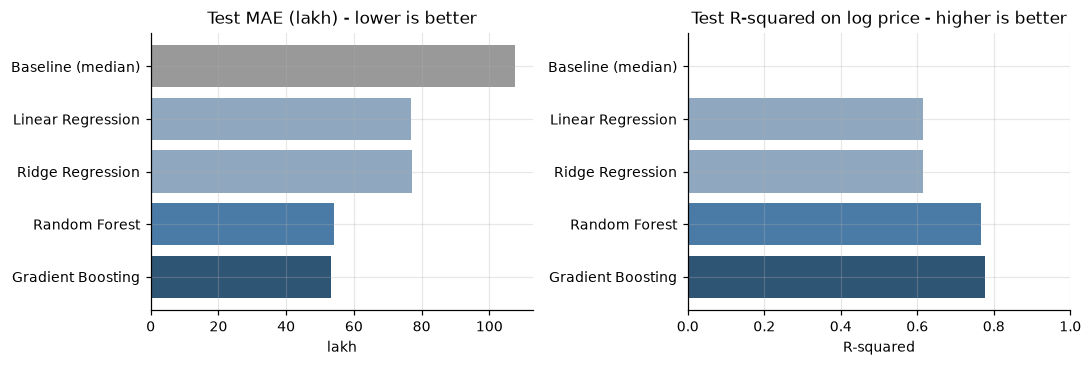

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
order = ["Baseline (median)", "Linear Regression", "Ridge Regression",
         "Random Forest", "Gradient Boosting"]

ax[0].barh(order, [final_rows[m]["MAE_lakh"] for m in order],
           color=["#999999", "#8fa8bf", "#8fa8bf", "#4a7ba7", "#2f5574"])
ax[0].set(title="Test MAE (lakh) - lower is better", xlabel="lakh")
ax[0].invert_yaxis()

r2 = [max(final_rows[m]["R2_log"], 0) for m in order]
ax[1].barh(order, r2, color=["#999999", "#8fa8bf", "#8fa8bf", "#4a7ba7", "#2f5574"])
ax[1].set(title="Test R-squared on log price - higher is better", xlabel="R-squared", xlim=(0, 1))
ax[1].invert_yaxis()

plt.tight_layout()
plt.savefig(FIG + "05_model_comparison.png", bbox_inches="tight")
plt.show()

## Where the best model goes wrong

A single average error hides the shape of the mistakes. Two diagnostics worth more than any
further tuning: predicted against actual, and the error broken down by price band.

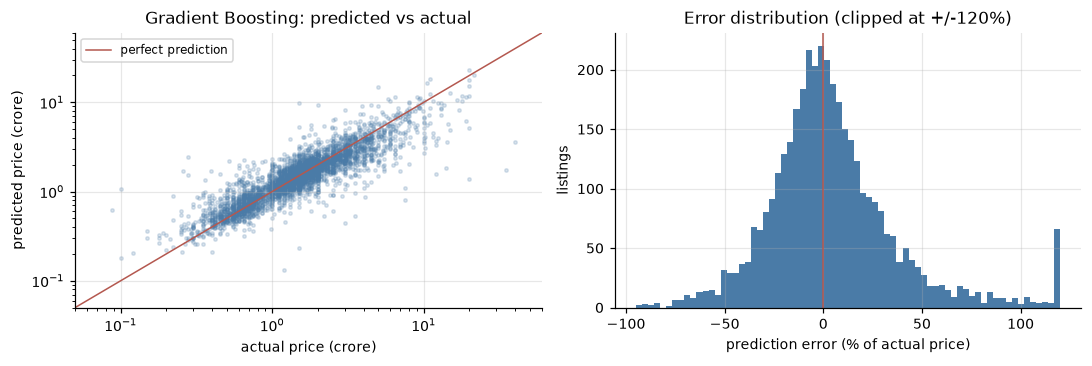

share of test listings predicted within 10% of the true price: 33.8%
share within 25%: 66.4%


In [13]:
best_pred_rupees = np.expm1(test_pred[best_name])
actual_rupees = test["price"].values

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))

ax[0].scatter(actual_rupees / CRORE, best_pred_rupees / CRORE, s=5, alpha=0.2, color="#4a7ba7")
lims = [0.05, 60]
ax[0].plot(lims, lims, color="#b4584f", lw=1, label="perfect prediction")
ax[0].set(xscale="log", yscale="log", xlim=lims, ylim=lims,
          xlabel="actual price (crore)", ylabel="predicted price (crore)",
          title=f"{best_name}: predicted vs actual")
ax[0].legend(fontsize=8)

pct_error = (best_pred_rupees - actual_rupees) / actual_rupees * 100
ax[1].hist(np.clip(pct_error, -120, 120), bins=70, color="#4a7ba7")
ax[1].axvline(0, color="#b4584f", lw=1)
ax[1].set(xlabel="prediction error (% of actual price)", ylabel="listings",
          title="Error distribution (clipped at +/-120%)")

plt.tight_layout()
plt.savefig(FIG + "06_prediction_quality.png", bbox_inches="tight")
plt.show()

print("share of test listings predicted within 10% of the true price:",
      f"{(np.abs(pct_error) <= 10).mean()*100:.1f}%")
print("share within 25%:", f"{(np.abs(pct_error) <= 25).mean()*100:.1f}%")

In [14]:
bands = pd.cut(actual_rupees / LAKH,
               bins=[0, 50, 100, 200, 500, 100000],
               labels=["under 50L", "50L-1Cr", "1-2Cr", "2-5Cr", "above 5Cr"])
band_table = pd.DataFrame({
    "listings": actual_rupees,
    "median_actual_lakh": actual_rupees / LAKH,
    "MAE_lakh": np.abs(best_pred_rupees - actual_rupees) / LAKH,
    "MedAPE_%": np.abs(pct_error)}).groupby(bands, observed=True).agg(
    listings=("listings", "size"),
    median_actual_lakh=("median_actual_lakh", "median"),
    MAE_lakh=("MAE_lakh", "mean"),
    MedAPE_pct=("MedAPE_%", "median")).round(1)
print("Error by price band,", best_name, "on the test set:")
print(band_table.to_string())

Error by price band, Gradient Boosting on the test set:
           listings  median_actual_lakh  MAE_lakh  MedAPE_pct
under 50L       289                40.0      17.0        26.2
50L-1Cr         783                70.0      18.8        16.0
1-2Cr          1738               150.0      30.0        13.7
2-5Cr           848               295.0      76.1        18.2
above 5Cr       210               700.0     333.3        32.7


### What the diagnostics say

The scatter hugs the diagonal through the middle of the market and fans out at both ends. The
error table makes the pattern precise: in percentage terms the model is at its best on
mid-market property and worst on the cheapest and the most expensive listings.

Both failures have the same cause - **thin data at the edges**. The scrape was organised by price
band, so the extremes are sparsely covered, and the most expensive listings are also the most
individual: a Rs 20 crore villa's price depends on finishes, plot shape and view, none of which
appear in 23 columns. The error histogram is roughly centred on zero, which is the thing to
check - a model that was systematically high or low everywhere would mean a bug in the log
transform, typically forgetting the `expm1` on the way back.

## What the model actually uses

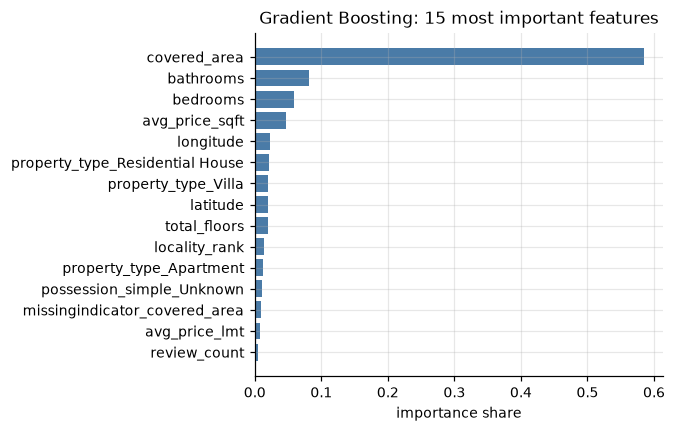

covered_area                       0.5847
bathrooms                          0.0813
bedrooms                           0.0590
avg_price_sqft                     0.0473
longitude                          0.0230
property_type_Residential House    0.0207
property_type_Villa                0.0202
latitude                           0.0200
total_floors                       0.0192
locality_rank                      0.0143
property_type_Apartment            0.0118
possession_simple_Unknown          0.0105
missingindicator_covered_area      0.0092
avg_price_lmt                      0.0076
review_count                       0.0053


In [15]:
feature_names = tuned[best_name].named_steps["pre"].get_feature_names_out()
model_step = tuned[best_name].named_steps["model"]
if hasattr(model_step, "feature_importances_"):
    importances = model_step.feature_importances_
else:
    # a linear model has no importances; the size of the standardised coefficient is the
    # closest equivalent, and it is comparable across features because of the scaling
    importances = np.abs(model_step.coef_)
imp = pd.Series(importances, index=[n.split("__", 1)[-1] for n in feature_names])
imp = imp.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(6.2, 4))
ax.barh(imp.index[::-1], imp.values[::-1], color="#4a7ba7")
ax.set(title=f"{best_name}: 15 most important features", xlabel="importance share")
plt.tight_layout()
plt.savefig(FIG + "07_feature_importance.png", bbox_inches="tight")
plt.show()

print(imp.round(4).to_string())

Area dominates, the locality price aggregates come next, then bathroom and bedroom counts.
That ordering is a sanity check in itself: it is exactly what a property valuer would say
matters, and it is strong evidence that no leaked column is doing the work. When a feature you
cannot explain tops this chart, the usual cause is leakage.

## Save the model and the numbers

In [16]:
joblib.dump(tuned[best_name], f"../models/{best_name.lower().replace(' ', '_')}.joblib")

summary = {
    "rows": {"train": int(len(train)), "test": int(len(test))},
    "features": {"numeric": NUMERIC, "categorical": CATEGORICAL,
                 "count": len(FEATURES), "after_preprocessing": int(matrix.shape[1])},
    "target": "log1p(price), scored back in rupees",
    "cross_validation": cv_table.to_dict(orient="index"),
    "locality_experiment": {f"{k[0]} | {k[1]}": v for k, v in experiment.items()},
    "chosen_hyperparameters": {k: {str(a): str(b) for a, b in v.items()}
                               for k, v in chosen_params.items()},
    "test_results": test_table.to_dict(orient="index"),
    "best_model": best_name,
    "within_10_pct": float((np.abs(pct_error) <= 10).mean() * 100),
    "within_25_pct": float((np.abs(pct_error) <= 25).mean() * 100),
    "error_by_band": band_table.to_dict(orient="index"),
    "top_features": imp.round(4).to_dict()}

with open("../reports/model_results.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("saved: models/" + best_name.lower().replace(" ", "_") + ".joblib")
print("saved: reports/model_results.json")

saved: models/gradient_boosting.joblib
saved: reports/model_results.json


---
# Conclusions

**What was built.** 19,340 cleaned listings, split 80/20. 23 features - 14 numeric, 9
categorical - out of 71 available columns, with 49 dropped for six stated reasons and 2
repaired. One `ColumnTransformer` doing median imputation with missing-indicators,
standardisation and one-hot encoding, wrapped in a `Pipeline` with each of four models so that
cross-validation refits the preprocessing on every fold.

**What worked.**

1. *Logging the target.* Skew 5.82 to 0.09. This single line does more for the linear models
   than any feature would have.
2. *Trees over linear models.* The gap is large and it is explained by interactions - the price
   per square foot is not a constant across Hyderabad, and only the trees can discover that
   without being told.
3. *Published locality aggregates over one-hot encoding.* Four numeric columns beat a hundred
   indicator columns, and they generalise to unseen localities.
4. *Missing-indicators.* `floor` is absent for 99.9% of villas - the absence itself is a feature.

**What to be honest about.**

- Percentage error is noticeably worse at the cheap and expensive ends of the market, because
  the price-band scrape covers them thinly.
- Validation is mildly optimistic wherever `avg_price_sqft` is used, since the website computed
  that average over a pool of listings that overlaps ours. The cleaning report flagged this and
  it has not gone away.
- This model predicts the **asking** price, which is what was scraped. It is not a valuation
  model and does not know what anything sold for.

**The obvious next steps**, in the order they are likely to pay off: parse `amenities` and
`flooring_type` into binary flags; try `HistGradientBoostingRegressor` or XGBoost, which handle
missing values natively and usually beat plain `GradientBoostingRegressor`; add target encoding
for locality, fitted strictly inside CV folds; and only then consider the description text,
after stripping the price out of it.